# PDF inspection and extraction checks

This notebook examines the source PDFs before they are used in the document analysis application. It checks whether text can be extracted, flags pages that may be scanned images, tests OCR and table extraction, and demonstrates how a cited passage can be located on its PDF page.

In [2]:
from pathlib import Path
import csv
import re
import pymupdf

PROJECT_DIR = Path.cwd()
PDF_DIR = PROJECT_DIR / "data" / "raw"
OUTPUT_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_FILE = OUTPUT_DIR / "page_inventory.csv"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

rows = []

for pdf_path in sorted(PDF_DIR.glob("*.pdf")):
    with pymupdf.open(pdf_path) as document:
        print(f"\n{pdf_path.name}: {len(document)} pages")

        for page_number, page in enumerate(document, start=1):
            text = page.get_text("text", sort=True).strip()
            compact_text = re.sub(r"\s+", "", text)

            rows.append({
                "document": pdf_path.name,
                "page_number": page_number,
                "character_count": len(compact_text),
                "possible_scanned_page": len(compact_text) < 80,
                "text": text,
            })

        candidates = [
            row["page_number"]
            for row in rows
            if row["document"] == pdf_path.name
            and row["possible_scanned_page"]
        ]
        print(f"Pages flagged for OCR review: {candidates or 'None'}")

with OUTPUT_FILE.open("w", newline="", encoding="utf-8") as csv_file:
    writer = csv.DictWriter(
        csv_file,
        fieldnames=[
            "document",
            "page_number",
            "character_count",
            "possible_scanned_page",
            "text",
        ],
    )
    writer.writeheader()
    writer.writerows(rows)

print(f"\nSaved page inventory to: {OUTPUT_FILE}")


edpb_fines_guidelines.pdf: 48 pages
Pages flagged for OCR review: [11]

gdpr_regulation.pdf: 88 pages
Pages flagged for OCR review: None

Saved page inventory to: /Users/shashankbangaru/Desktop/LexiSyncAI/data/processed/page_inventory.csv


## Inspect a page flagged for possible OCR

The page inventory marks EDPB PDF page 11 as having very little extractable text. This cell displays the page image alongside the extracted text so I can check whether the page is a scanned diagram or whether text extraction failed. The visual check helps decide whether OCR is needed.

Extracted text:
DIAGRAM





                                                                                   11
 Adopted


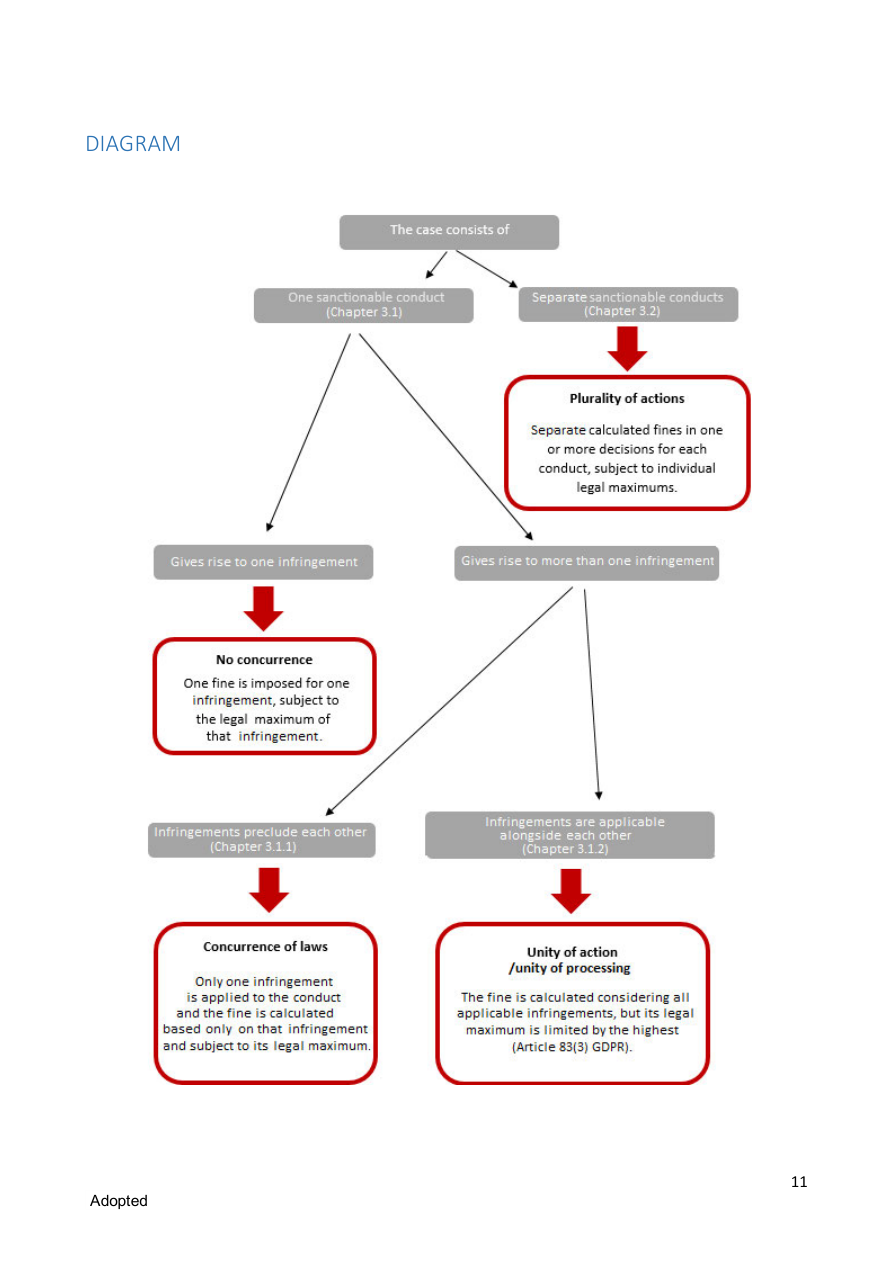

In [3]:
from pathlib import Path
import pymupdf
from IPython.display import Image, display

pdf_path = Path.home() / "Desktop/LexiSyncAI/data/raw/edpb_fines_guidelines.pdf"

with pymupdf.open(pdf_path) as document:
    page = document[10]  # PDF page 11; Python uses zero-based indexing

    print("Extracted text:")
    print(page.get_text("text", sort=True) or "[No text extracted]")

    image = page.get_pixmap(
        matrix=pymupdf.Matrix(1.5, 1.5),
        alpha=False,
    )
    display(Image(data=image.tobytes("png")))

## Check whether GDPR Article 83 text is extractable

Before relying on Article 83 in the project, I search the GDPR PDF for text associated with administrative fines. This confirms that the relevant section is present in the PDF’s extracted text and helps locate it for a more focused inspection.

In [4]:
from pathlib import Path
import pymupdf

pdf_path = Path.home() / "Desktop/LexiSyncAI/data/raw/gdpr_regulation.pdf"

with pymupdf.open(pdf_path) as document:
    for page_number, page in enumerate(document, start=1):
        text = page.get_text("text", sort=True)

        if "83" in text and ("administrative fines" in text.lower() or "€20 000 000" in text):
            print(f"\n--- PDF page {page_number} ---")
            print(text[:2500])
            


--- PDF page 77 ---
4.5.2016         EN                           Official Journal of the European Union                                L 119/77


        (b)  advise the Commission on any issue related to the protection of personal data in the Union, including on any
          proposed amendment of this Regulation;


         (c)  advise the Commission on the format and procedures  for the exchange of information between  controllers,
           processors and supervisory authorities for binding corporate rules;


        (d)  issue guidelines, recommendations, and best practices on procedures for erasing links, copies or replications of
           personal data from publicly available communication services as referred to in Article 17(2);


         (e)  examine, on its own initiative, on request of one of its members or on request of the Commission, any question
           covering the application of this Regulation and issue guidelines, recommendations and best practices in order

## Locate the complete GDPR Article 83 section

This search uses several distinctive phrases from Article 83 to find the page where the article begins. It prints the surrounding text so I can verify that the section on administrative fines is being extracted correctly.

In [5]:
from pathlib import Path
import pymupdf

pdf_path = Path.home() / "Desktop/LexiSyncAI/data/raw/gdpr_regulation.pdf"

with pymupdf.open(pdf_path) as document:
    for page_number, page in enumerate(document, start=1):
        text = page.get_text("text", sort=True)
        normalized_text = " ".join(text.lower().split())

        if (
            "general conditions for imposing administrative fines" in normalized_text
            or "article 83(4)" in normalized_text
            or "article 83(5)" in normalized_text
            or "20 000 000" in normalized_text
        ):
            print(f"\n--- PDF page {page_number} ---")
            print(text[:3500])


--- PDF page 82 ---
L 119/82         EN                           Official Journal of the European Union                                  4.5.2016


       6.   Court proceedings for exercising the right to receive compensation shall be brought before the courts competent
      under the law of the Member State referred to in Article 79(2).




                                                                         Article 83


                                General conditions for imposing administrative fines


       1.   Each supervisory authority shall ensure that the imposition of administrative fines pursuant to this Article in
       respect of infringements of this Regulation referred to in paragraphs 4, 5 and 6 shall in each individual case be effective,
      proportionate and dissuasive.


       2.    Administrative fines shall, depending on the circumstances of each individual case, be imposed in addition to, or
       instead of, measures referred to in points (a) to (

In [6]:
from pathlib import Path
import pymupdf

pdf_path = Path.home() / "Desktop/LexiSyncAI/data/raw/gdpr_regulation.pdf"

with pymupdf.open(pdf_path) as document:
    for page_number in (82, 83, 84):
        page = document[page_number - 1]
        print(f"\n--- PDF page {page_number} ---")
        print(page.get_text("text", sort=True))


--- PDF page 82 ---
L 119/82         EN                           Official Journal of the European Union                                  4.5.2016


       6.   Court proceedings for exercising the right to receive compensation shall be brought before the courts competent
      under the law of the Member State referred to in Article 79(2).




                                                                         Article 83


                                General conditions for imposing administrative fines


       1.   Each supervisory authority shall ensure that the imposition of administrative fines pursuant to this Article in
       respect of infringements of this Regulation referred to in paragraphs 4, 5 and 6 shall in each individual case be effective,
      proportionate and dissuasive.


       2.    Administrative fines shall, depending on the circumstances of each individual case, be imposed in addition to, or
       instead of, measures referred to in points (a) to (

## Bonus 1 — Review the page inventory

I load the page inventory created during PDF inspection. It contains each PDF’s page number, extracted character count, possible scanned-page flag, and extracted text. Reviewing a few rows confirms that the inventory was saved and can be used by later OCR checks.

In [10]:
import pandas as pd
from pathlib import Path

inventory_path = (
    Path.home()
    / "Desktop"
    / "LexiSyncAI"
    / "data"
    / "processed"
    / "page_inventory.csv"
)

page_inventory = pd.read_csv(inventory_path)

print("Inventory file:", inventory_path)
print("Columns:", page_inventory.columns.tolist())
display(page_inventory.head(3))

Inventory file: /Users/shashankbangaru/Desktop/LexiSyncAI/data/processed/page_inventory.csv
Columns: ['document', 'page_number', 'character_count', 'possible_scanned_page', 'text']


,document,page_number,character_count,possible_scanned_page,text
0,edpb_fines_guidelines.pdf,1,101,False,Guidelines 04/2022 on the calculation of admin...
1,edpb_fines_guidelines.pdf,2,185,False,Version history\n\n\nVersion 1.0 12 May 2022...
2,edpb_fines_guidelines.pdf,3,2483,False,EXECUTIVE SUMMARY\n\n\nThe European Data Prote...


## Bonus 1 — Detect scanned pages and apply OCR when needed

Pages with very little extractable text are treated as possible scans. This cell checks those flags and, when Tesseract is available, renders each flagged PDF page as an image and runs OCR on it. The OCR text and status are saved for evaluation. OCR is used as a fallback because image-based pages may not contain text that normal PDF extraction can read.

In [14]:
## Check scanned-page flags and OCR fallback

import shutil
import fitz
import pandas as pd
import pytesseract
from PIL import Image
from pathlib import Path

PROJECT_ROOT = Path.home() / "Desktop" / "LexiSyncAI"
RAW_DIR = PROJECT_ROOT / "data" / "raw"

# The page inventory was loaded in the previous cell.
flagged_pages = page_inventory[
    page_inventory["possible_scanned_page"].astype(str).str.lower().isin(
        ["true", "1", "yes"]
    )
].copy()

print("Pages flagged for OCR review:")
if flagged_pages.empty:
    print("None. The inventory did not identify any scanned pages.")
else:
    display(flagged_pages[["document", "page_number", "character_count"]])

# Tesseract is the local OCR engine used for the fallback.
if shutil.which("tesseract") is None:
    print(
        "\nOCR fallback unavailable: Tesseract is not installed or not on PATH."
    )
    print("On macOS, install it in Terminal with: brew install tesseract")
else:
    ocr_rows = []

    for _, row in flagged_pages.iterrows():
        pdf_path = RAW_DIR / row["document"]
        page_number = int(row["page_number"])  # inventory uses 1-based pages

        try:
            with fitz.open(pdf_path) as pdf:
                page = pdf[page_number - 1]
                pix = page.get_pixmap(matrix=fitz.Matrix(2, 2), alpha=False)
                image = Image.frombytes("RGB", [pix.width, pix.height], pix.samples)

            ocr_text = pytesseract.image_to_string(image, lang="eng").strip()

            ocr_rows.append({
                "document": row["document"],
                "page_number": page_number,
                "native_character_count": int(row["character_count"]),
                "ocr_character_count": len(ocr_text),
                "ocr_text": ocr_text,
                "fallback_status": "OCR completed" if ocr_text else "OCR returned no text",
            })

        except Exception as error:
            ocr_rows.append({
                "document": row["document"],
                "page_number": page_number,
                "native_character_count": int(row["character_count"]),
                "ocr_character_count": 0,
                "ocr_text": "",
                "fallback_status": f"OCR failed: {error}",
            })

    ocr_results = pd.DataFrame(ocr_rows)

    if ocr_results.empty:
        print("\nNo pages required OCR fallback.")
    else:
        display(ocr_results)
        output_path = PROJECT_ROOT / "data" / "evaluation" / "ocr_fallback_results.csv"
        output_path.parent.mkdir(parents=True, exist_ok=True)
        ocr_results.to_csv(output_path, index=False)
        print("Saved OCR results to:", output_path)

Pages flagged for OCR review:


,document,page_number,character_count
10,edpb_fines_guidelines.pdf,11,16


,document,page_number,native_character_count,ocr_character_count,ocr_text,fallback_status
0,edpb_fines_guidelines.pdf,11,16,828,DIAGRAM\n\nan\n\n(Chapter 3.1)\n\nGives rise t...,OCR completed


Saved OCR results to: /Users/shashankbangaru/Desktop/LexiSyncAI/data/evaluation/ocr_fallback_results.csv


## Summarize OCR results

This cell displays a compact summary of the OCR output, including the document, page number, number of characters recognized, and processing status. It makes it easy to check whether OCR recovered text from a page that had little or no native text.

In [15]:
if "ocr_results" in globals() and not ocr_results.empty:
    display(
        ocr_results[
            ["document", "page_number", "ocr_character_count", "fallback_status"]
        ]
    )
else:
    print("No OCR result was produced. Check whether Tesseract is installed.")

,document,page_number,ocr_character_count,fallback_status
0,edpb_fines_guidelines.pdf,11,828,OCR completed


## Bonus 2 — Extract tables from the PDFs

PDF tables can contain useful information that ordinary text extraction may flatten or misorder. This cell searches every page for table structures, records their locations and dimensions, and displays examples. The output also helps identify extraction errors that may need manual checking before table content is used.

In [16]:
import fitz
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path.home() / "Desktop" / "LexiSyncAI"
RAW_DIR = PROJECT_ROOT / "data" / "raw"

table_pages = []

for pdf_path in RAW_DIR.glob("*.pdf"):
    with fitz.open(pdf_path) as pdf:
        for page_index, page in enumerate(pdf):
            tables = page.find_tables().tables

            for table_index, table in enumerate(tables, start=1):
                extracted = table.extract()
                if extracted:
                    table_pages.append({
                        "document": pdf_path.name,
                        "page_number": page_index + 1,
                        "table_number": table_index,
                        "rows": len(extracted),
                        "columns": max(len(row) for row in extracted),
                        "table_data": extracted,
                    })

print(f"Tables detected: {len(table_pages)}")
for table in table_pages[:5]:
    print(
        f"\n{table['document']} — page {table['page_number']}, "
        f"{table['rows']} rows × {table['columns']} columns"
    )
    display(pd.DataFrame(table["table_data"]))

Tables detected: 6

edpb_fines_guidelines.pdf — page 2, 3 rows × 3 columns


,0,1,2
0,Version1 0\n.,12May2022,AdoptionoftheGuidelinesfor public consultation
1,Version2 0\n.,24May2023,AdoptionoftheGuidelinesafterpublic consultation
2,Version2 1\n.,29June 2023,Minorcorrection



edpb_fines_guidelines.pdf — page 44, 4 rows × 7 columns


,0,1,2,3,4,5,6
0,,Lowlevelofseriousness,None,Mediumlevelof\nseriousness,None,Highlevelofseriousness,None
1,,Static\nrange,Dynamic\nrangeinthe\ncaseofa\nturnover\n>500m,Static\nrange,Dynamicrange\ninthecaseofa\nturnover\n>500m,Static\nrange,Dynamic\nrangeinthe\ncaseofa\nturnover\n>500m
2,83(4)GDPR,0 -1m,0 0 .2% of the\n-\nannual\nturnover,1m-2m,0 .2% 0 .4% of\n-\ntheannual\nturnover,2m-10m,0 .4% 2% of\n-\ntheannual\nturnover
3,83(5)(6)GDPR,0 –2m,0 0 .4% of the\n-\nannual\nturnover,2m-4m,0 .4% 0 .8% of\n-\ntheannual\nturnover,4m-20m,0 .8% 4% of\n-\ntheannual\nturnover



edpb_fines_guidelines.pdf — page 44, 3 rows × 4 columns


,0,1,2,3
0,,Lowlevelofseriousness,Mediumlevelof\nseriousness,Highlevelofseriousness
1,Undertakingswitha\nturnoverof€250mup\nuntil€500m,40 -100%ofthestartingamount,None,None
2,None,0 –1m,"400 ,000 2m\n–","800 ,000 10m\n–"



edpb_fines_guidelines.pdf — page 45, 11 rows × 4 columns


,0,1,2,3
0,,Lowlevelofseriousness,Mediumlevelof\nseriousness,Highlevelofseriousness
1,Undertakingswitha\nturnoverof€100mup\nuntil€250m,15 -50%ofthestartingamount,None,None
2,None,"0 500 000\n– ,","150 ,000 1m\n–","300 ,000 5m\n–"
3,Undertakingswitha\nturnoverof€50mup\nuntil€100m,8 -20%ofthestartingamount,None,None
4,None,"0 200 000\n– ,","80 000 400 000\n, – ,","160 ,000 2m\n–"
5,Undertakingswitha\nturnoverof€10mup\nuntil€50m,1 .5 10% of the starting amount\n-,None,None
6,None,"0 100 000\n– ,","15 000 200 000\n, – ,","30 ,000 1m\n–"
7,Undertakingswitha\nturnoverof€2mup\nuntil€10m,0 .3 2% of the starting amount\n-,None,None
8,None,"0 20 000\n– ,","3 000 40 000\n, – ,","6 000 200 000\n, – ,"
9,Undertakingswitha\nturnoverupuntil€2m,0 .2 0 .4% of the starting amount\n-,None,None



edpb_fines_guidelines.pdf — page 46, 12 rows × 4 columns


,0,1,2,3
0,,Lowlevelof\nseriousness,Mediumlevelof\nseriousness,Highlevelofseriousness
1,Undertakingswitha\nturnoverof€250mup\nuntil€500m,40 -100%ofthestartingamount,None,None
2,None,0 –2m,"800 ,000 4m\n–",1 .6m 20m\n–
3,Undertakingswitha\nturnoverof€100mup\nuntil€250m,15 -50%ofthestartingamount,None,None
4,None,0 –1m,"300 ,000 2m\n–","600 ,000 10m\n–"
5,Undertakingswitha\nturnoverof€50mup\nuntil€100m,8 -20%ofthestartingamount,None,None
6,None,"0 400 000\n– ,","160 000 800 000\n, – ,","320 ,000 4m\n–"
7,Undertakingswitha\nturnoverof€10mup\nuntil€50m,1 .5 10% of the starting amount\n-,None,None
8,None,"0 200 000\n– ,","30 000 400 000\n, – ,","60 ,000 2m\n–"
9,Undertakingswitha\nturnoverof€2mup\nuntil€10m,0 .3 2% of the starting amount\n-,None,None


## Review all detected tables

This cell displays each table found in the PDFs, along with its document, page, and table number. Reviewing the results helps assess whether the PDF table extraction preserved the content and layout well enough for further use.

In [17]:
for table in table_pages:
    print(
        f"\n{table['document']} — page {table['page_number']}, "
        f"table {table['table_number']}"
    )
    display(pd.DataFrame(table["table_data"]))


edpb_fines_guidelines.pdf — page 2, table 1


,0,1,2
0,Version1 0\n.,12May2022,AdoptionoftheGuidelinesfor public consultation
1,Version2 0\n.,24May2023,AdoptionoftheGuidelinesafterpublic consultation
2,Version2 1\n.,29June 2023,Minorcorrection



edpb_fines_guidelines.pdf — page 44, table 1


,0,1,2,3,4,5,6
0,,Lowlevelofseriousness,None,Mediumlevelof\nseriousness,None,Highlevelofseriousness,None
1,,Static\nrange,Dynamic\nrangeinthe\ncaseofa\nturnover\n>500m,Static\nrange,Dynamicrange\ninthecaseofa\nturnover\n>500m,Static\nrange,Dynamic\nrangeinthe\ncaseofa\nturnover\n>500m
2,83(4)GDPR,0 -1m,0 0 .2% of the\n-\nannual\nturnover,1m-2m,0 .2% 0 .4% of\n-\ntheannual\nturnover,2m-10m,0 .4% 2% of\n-\ntheannual\nturnover
3,83(5)(6)GDPR,0 –2m,0 0 .4% of the\n-\nannual\nturnover,2m-4m,0 .4% 0 .8% of\n-\ntheannual\nturnover,4m-20m,0 .8% 4% of\n-\ntheannual\nturnover



edpb_fines_guidelines.pdf — page 44, table 2


,0,1,2,3
0,,Lowlevelofseriousness,Mediumlevelof\nseriousness,Highlevelofseriousness
1,Undertakingswitha\nturnoverof€250mup\nuntil€500m,40 -100%ofthestartingamount,None,None
2,None,0 –1m,"400 ,000 2m\n–","800 ,000 10m\n–"


... (2 outputs left out)


edpb_fines_guidelines.pdf — page 46, table 1


,0,1,2,3
0,,Lowlevelof\nseriousness,Mediumlevelof\nseriousness,Highlevelofseriousness
1,Undertakingswitha\nturnoverof€250mup\nuntil€500m,40 -100%ofthestartingamount,None,None
2,None,0 –2m,"800 ,000 4m\n–",1 .6m 20m\n–
3,Undertakingswitha\nturnoverof€100mup\nuntil€250m,15 -50%ofthestartingamount,None,None
4,None,0 –1m,"300 ,000 2m\n–","600 ,000 10m\n–"
5,Undertakingswitha\nturnoverof€50mup\nuntil€100m,8 -20%ofthestartingamount,None,None
6,None,"0 400 000\n– ,","160 000 800 000\n, – ,","320 ,000 4m\n–"
7,Undertakingswitha\nturnoverof€10mup\nuntil€50m,1 .5 10% of the starting amount\n-,None,None
8,None,"0 200 000\n– ,","30 000 400 000\n, – ,","60 ,000 2m\n–"
9,Undertakingswitha\nturnoverof€2mup\nuntil€10m,0 .3 2% of the starting amount\n-,None,None



edpb_fines_guidelines.pdf — page 47, table 1


,0,1,2
0,Lowlevelof,Mediumlevelof,Highlevelofseriousness
1,seriousness,seriousness,
2,"0 8 000\n– ,","4 000 16 000\n, – ,","8 000 80 000\n, – ,"


## Validate table extraction against a manual reference

I use the EDPB guidelines’ version-history table as a small validation example. I manually transcribe its contents from the PDF, normalize spacing and punctuation, and compare each extracted cell with the reference. This gives a simple cell-level accuracy check; it validates this example only, not every table in the documents.

In [18]:
## Compare extracted table with manually checked ground truth

import re
import pandas as pd

# First detected table: EDPB version history, PDF page 2.
extracted_table = table_pages[0]["table_data"]

# Manually transcribed from the PDF page.
ground_truth = [
    ["Version 1.0", "12 May 2022",
     "Adoption of the Guidelines for public consultation"],
    ["Version 2.0", "24 May 2023",
     "Adoption of the Guidelines after public consultation"],
    ["Version 2.1", "29 June 2023",
     "Minor correction"],
]

def normalize_cell(value):
    """Ignore spacing and punctuation differences from PDF extraction."""
    if value is None:
        return ""
    return re.sub(r"[^a-z0-9]", "", str(value).lower())

# Compare corresponding cells.
total_cells = 0
matching_cells = 0
mismatches = []

for row_index, expected_row in enumerate(ground_truth):
    extracted_row = extracted_table[row_index] if row_index < len(extracted_table) else []

    for col_index, expected_value in enumerate(expected_row):
        actual_value = (
            extracted_row[col_index]
            if col_index < len(extracted_row)
            else ""
        )

        total_cells += 1
        if normalize_cell(actual_value) == normalize_cell(expected_value):
            matching_cells += 1
        else:
            mismatches.append({
                "row": row_index + 1,
                "column": col_index + 1,
                "expected": expected_value,
                "extracted": actual_value,
            })

cell_accuracy = matching_cells / total_cells if total_cells else 0

print(f"Cells matched: {matching_cells}/{total_cells}")
print(f"Cell-level accuracy: {cell_accuracy:.1%}")

if mismatches:
    print("\nCells needing review:")
    display(pd.DataFrame(mismatches))
else:
    print("All manually checked cells matched after normalization.")

Cells matched: 9/9
Cell-level accuracy: 100.0%
All manually checked cells matched after normalization.


## Bonus 3 — Locate a cited passage on the PDF page

A citation is more useful when the cited passage can be found on the original page. This demonstration searches for a short quote from GDPR Article 6, highlights its location, and saves an image of the highlighted page. It checks that the quote and page reference can be connected to a visible location in the source PDF.

Quote: Processing shall be lawful only if
PDF page: 36
Bounding boxes found: 1
Bounding box coordinates: [(89.0, 320.3, 213.3, 329.9)]
Saved highlighted page to: /Users/shashankbangaru/Desktop/LexiSyncAI/data/evaluation/bbox_citation_demo.png


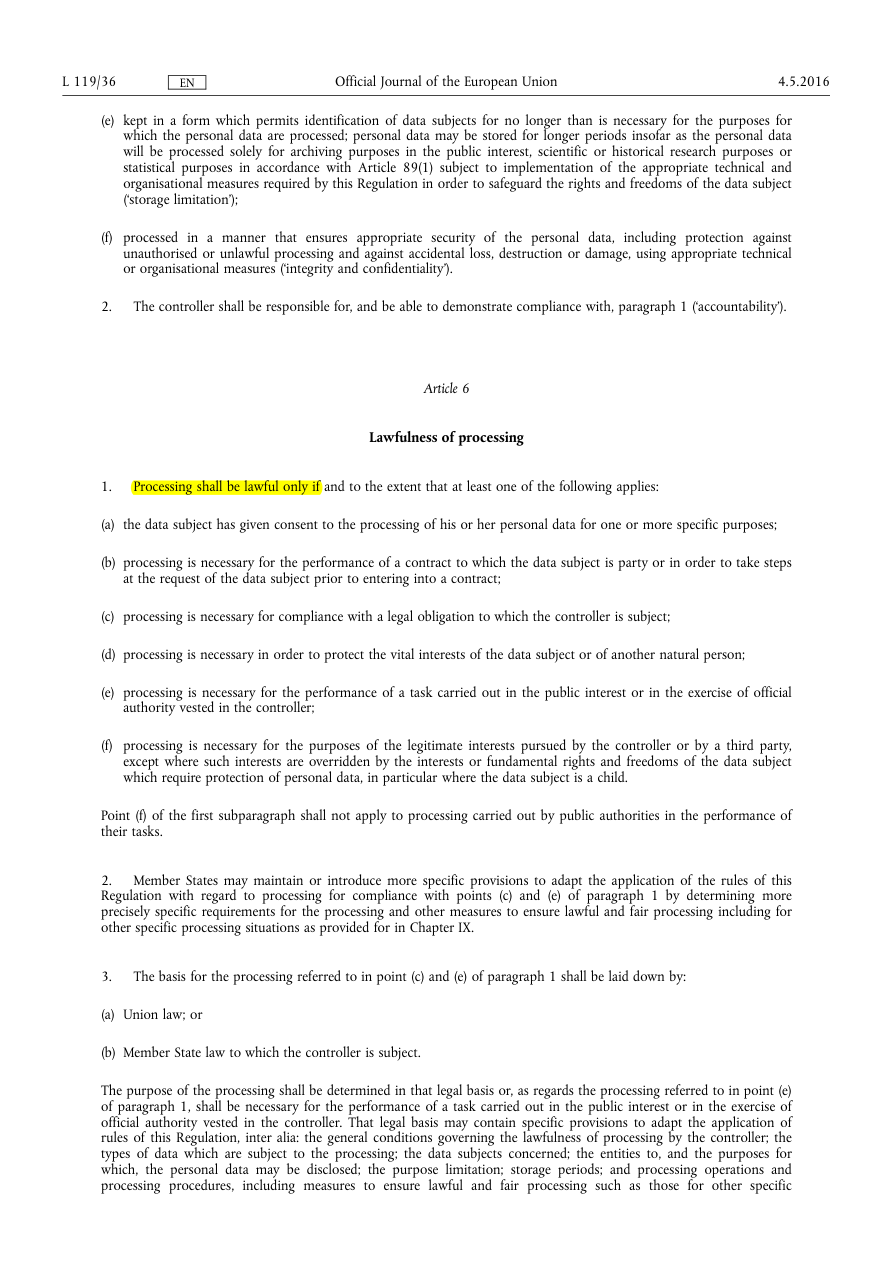

In [19]:
## Find and highlight a cited passage on its PDF page

import fitz
from pathlib import Path
from IPython.display import Image, display

PROJECT_ROOT = Path.home() / "Desktop" / "LexiSyncAI"
PDF_PATH = PROJECT_ROOT / "data" / "raw" / "gdpr_regulation.pdf"
OUTPUT_PATH = PROJECT_ROOT / "data" / "evaluation" / "bbox_citation_demo.png"

# Short quote from GDPR Article 6, shown earlier in retrieval results.
QUOTE = "Processing shall be lawful only if"

PDF_PAGE_NUMBER = 36  # Human-readable page number; PyMuPDF uses zero-based indexes.

with fitz.open(PDF_PATH) as pdf:
    page = pdf[PDF_PAGE_NUMBER - 1]
    rectangles = page.search_for(QUOTE)

    if not rectangles:
        raise ValueError(
            f"Could not find the quote on PDF page {PDF_PAGE_NUMBER}. "
            "Check the quote and page number against the cited evidence."
        )

    for rectangle in rectangles:
        page.add_highlight_annot(rectangle)

    OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
    pixmap = page.get_pixmap(matrix=fitz.Matrix(1.5, 1.5), annots=True)
    pixmap.save(OUTPUT_PATH)

print(f"Quote: {QUOTE}")
print(f"PDF page: {PDF_PAGE_NUMBER}")
print(f"Bounding boxes found: {len(rectangles)}")
print("Bounding box coordinates:", [tuple(round(v, 1) for v in r) for r in rectangles])
print("Saved highlighted page to:", OUTPUT_PATH)

display(Image(filename=str(OUTPUT_PATH)))